In [1]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not available — switch Colab runtime to T4 GPU.")

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [2]:

from pathlib import Path
from google.colab import drive
import pandas as pd
import torch

# --------------------------------------------------
# 1. Connect to the correct Google Drive
# --------------------------------------------------
mount_candidates = [
    "/content/drive5",
    "/content/drive6",
    "/content/drive7",
    "/content/drive8",
    "/content/drive9",
]

MOUNT = None

for candidate in mount_candidates:
    p = Path(candidate)
    project_path = p / "MyDrive/Ocular_Project"

    # Reuse a mount only when it contains the expected project files.
    if (
        (project_path / "datasets").is_dir()
        and (project_path / "results").is_dir()
    ):
        MOUNT = p
        print("Using existing project mount:", MOUNT)
        break

    # Otherwise mount at a fresh, empty location.
    if not p.exists() or not any(p.iterdir()):
        MOUNT = p
        drive.mount(str(MOUNT))
        break

if MOUNT is None:
    raise RuntimeError(
        "No suitable mount point found. Inspect existing /content/drive* folders."
    )

PROJECT = MOUNT / "MyDrive/Ocular_Project"

# --------------------------------------------------
# 2. Verify required files
# --------------------------------------------------
SPLIT_CSV = (
    PROJECT / "results/IITD/notebook04_baseline_recognition/"
    "IITD_baseline_dataset_split.csv"
)
PREPROCESS_CSV = (
    PROJECT / "results/IITD/notebook02_preprocessing/"
    "IITD_preprocessed_metadata.csv"
)

required = [SPLIT_CSV, PREPROCESS_CSV]

for p in required:
    print(f"{p.name}: {p.exists()}")
    if not p.is_file():
        raise FileNotFoundError(f"Required file missing: {p}")

split_df = pd.read_csv(SPLIT_CSV)
preprocess_df = pd.read_csv(PREPROCESS_CSV)

print("\nBaseline split counts:")
print(split_df["split"].value_counts())

print("\nSplit columns:", split_df.columns.tolist())
print("Preprocessing columns:", preprocess_df.columns.tolist())

# --------------------------------------------------
# 3. Confirm GPU
# --------------------------------------------------
print("\nPyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError(
        "GPU unavailable. Select Runtime > Change runtime type > T4 GPU."
    )

print("GPU:", torch.cuda.get_device_name(0))

# --------------------------------------------------
# 4. Prepare output locations
# --------------------------------------------------
OUT_DIR = PROJECT / "results/IITD/notebook06_gan_augmentation"
MODEL_DIR = PROJECT / "models/IITD"

OUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("\nProject root:", PROJECT)
print("Results folder:", OUT_DIR)
print("Model folder:", MODEL_DIR)
print("\nCell 1 complete. No training has started.")


Mounted at /content/drive5
IITD_baseline_dataset_split.csv: True
IITD_preprocessed_metadata.csv: True

Baseline split counts:
split
train         1526
test           436
validation     218
Name: count, dtype: int64

Split columns: ['image_path', 'relative_path', 'filename', 'subject_original', 'eye_original', 'capture_id_original', 'extension', 'valid_image', 'width_original', 'height_original', 'mode_original', 'format', 'file_size_bytes', 'original_relative_path', 'processed_path', 'subject_processed', 'eye_processed', 'capture_id_processed', 'width_processed', 'height_processed', 'mode_processed', 'path_exists', 'subject', 'eye', 'label_name', 'label', 'split']
Preprocessing columns: ['original_relative_path', 'processed_path', 'subject', 'eye', 'capture_id', 'width', 'height', 'mode']

PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4

Project root: /content/drive5/MyDrive/Ocular_Project
Results folder: /content/drive5/MyDrive/Ocular_Project/results/IITD/notebook06_gan_augme

In [3]:

from pathlib import Path
from PIL import Image
from collections import Counter
import pandas as pd

# --------------------------------------------------
# 1. Inspect identity-label distribution
# --------------------------------------------------
train_df = split_df[split_df["split"] == "train"].copy()

print("Training images:", len(train_df))
print("Unique identity labels:", train_df["label"].nunique())
print("Unique label names:", train_df["label_name"].nunique())

samples_per_class = train_df.groupby("label")["relative_path"].count()

print("\nTraining images per class:")
print(samples_per_class.value_counts().sort_index())

print("\nExample training records:")
display(
    train_df[
        ["original_relative_path", "processed_path",
         "subject", "eye", "label_name", "label"]
    ].head()
)

# --------------------------------------------------
# 2. Check whether Notebook 05's local cache survives
# --------------------------------------------------
CACHE_DIR = Path("/content/IITD_traditional_aug_cache")
CACHE_MANIFEST = CACHE_DIR / "training_manifest.csv"

if CACHE_MANIFEST.is_file():
    cache_df = pd.read_csv(CACHE_MANIFEST)
    if "local_path" in cache_df.columns:
        existing = cache_df["local_path"].map(
            lambda p: Path(str(p)).is_file()
        ).sum()
        print(
            f"\nExisting local cache: {existing}/"
            f"{len(cache_df)} files available"
        )
    else:
        print("\nLocal cache manifest exists but has no local_path column.")
else:
    print("\nNotebook 05 local cache is not available in this runtime.")

# --------------------------------------------------
# 3. Find preprocessed images using relative paths
# --------------------------------------------------
IMAGE_DIR = (
    PROJECT / "results/IITD/notebook02_preprocessing/images_224"
)

if not IMAGE_DIR.is_dir():
    raise FileNotFoundError(
        f"Preprocessed image directory not found: {IMAGE_DIR}"
    )

def find_processed_image(row):
    # Prefer the original relative path, changing the extension
    # because Notebook 02 saved preprocessed images as PNG.
    rel = Path(str(row["original_relative_path"])).with_suffix(".png")
    candidate = IMAGE_DIR / rel
    if candidate.is_file():
        return candidate

    # Fallback: match by the subject-relative filename.
    matches = list(IMAGE_DIR.rglob(rel.name))
    if len(matches) == 1:
        return matches[0]

    return None

train_df["gan_source_path"] = train_df.apply(
    find_processed_image, axis=1
)

found = train_df["gan_source_path"].notna().sum()
print(f"\nTraining source images found: {found}/{len(train_df)}")

if found:
    print("Example resolved path:", train_df.loc[
        train_df["gan_source_path"].notna(),
        "gan_source_path"
    ].iloc[0])

    with Image.open(
        train_df.loc[
            train_df["gan_source_path"].notna(),
            "gan_source_path"
        ].iloc[0]
    ) as im:
        print("Example image size:", im.size)
        print("Example image mode:", im.mode)

if found != len(train_df):
    missing = train_df.loc[
        train_df["gan_source_path"].isna(),
        "original_relative_path"
    ].head(10).tolist()
    print("Example missing paths:", missing)
    raise RuntimeError(
        "Some training images could not be located. "
        "Stop here and send me the output."
    )

print("\nCell 2 complete. All training image paths are verified.")


Training images: 1526
Unique identity labels: 425
Unique label names: 425

Training images per class:
relative_path
3    207
4    207
7     11
Name: count, dtype: int64

Example training records:


,original_relative_path,processed_path,subject,eye,label_name,label
0,001/01_L.bmp,/content/drive5/MyDrive/Ocular_Project/results...,1,L,001_L,0
1,001/02_L.bmp,/content/drive5/MyDrive/Ocular_Project/results...,1,L,001_L,0
3,001/04_L.bmp,/content/drive5/MyDrive/Ocular_Project/results...,1,L,001_L,0
4,001/05_L.bmp,/content/drive5/MyDrive/Ocular_Project/results...,1,L,001_L,0
5,001/06_R.bmp,/content/drive5/MyDrive/Ocular_Project/results...,1,R,001_R,1



Notebook 05 local cache is not available in this runtime.

Training source images found: 1526/1526
Example resolved path: /content/drive5/MyDrive/Ocular_Project/results/IITD/notebook02_preprocessing/images_224/001/01_L.png
Example image size: (224, 224)
Example image mode: L

Cell 2 complete. All training image paths are verified.


In [4]:

from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm
import pandas as pd
import shutil
import json

# --------------------------------------------------
# 1. Create local cache
# --------------------------------------------------
GAN_CACHE = Path("/content/IITD_gan_cache")
GAN_IMAGES = GAN_CACHE / "real_train_images"
GAN_IMAGES.mkdir(parents=True, exist_ok=True)

manifest_rows = []
failed = []

# --------------------------------------------------
# 2. Copy only training images
# --------------------------------------------------
for row in tqdm(
    train_df.itertuples(index=False),
    total=len(train_df),
    desc="Caching GAN training images"
):
    src = Path(row.gan_source_path)
    # Keep a simple unique filename and preserve class label in metadata.
    dst = GAN_IMAGES / f"label_{int(row.label):03d}_{src.stem}.png"

    try:
        if not dst.is_file():
            with Image.open(src) as im:
                im.convert("L").save(dst, format="PNG")

        manifest_rows.append({
            "local_path": str(dst),
            "original_relative_path": row.original_relative_path,
            "subject": row.subject,
            "eye": row.eye,
            "label_name": row.label_name,
            "label": int(row.label),
            "split": row.split,
        })
    except Exception as e:
        failed.append({
            "source": str(src),
            "error": str(e)
        })

manifest_df = pd.DataFrame(manifest_rows)
manifest_path = GAN_CACHE / "gan_training_manifest.csv"
manifest_df.to_csv(manifest_path, index=False)

# --------------------------------------------------
# 3. Validate the cache
# --------------------------------------------------
print("\nExpected training images:", len(train_df))
print("Cached images:", len(manifest_df))
print("Failed copies:", len(failed))
print("Unique cached labels:", manifest_df["label"].nunique())
print("Manifest:", manifest_path)
print("Local image directory:", GAN_IMAGES)

if failed:
    pd.DataFrame(failed).to_csv(
        GAN_CACHE / "cache_errors.csv", index=False
    )
    print("First failures:", failed[:5])

if len(manifest_df) != len(train_df) or failed:
    raise RuntimeError(
        "Cache verification failed. Do not start GAN training."
    )

assert manifest_df["split"].eq("train").all()
assert manifest_df["local_path"].map(
    lambda p: Path(p).is_file()
).all()

with Image.open(manifest_df.iloc[0]["local_path"]) as im:
    print("Sample image size:", im.size)
    print("Sample image mode:", im.mode)

summary = {
    "training_images": int(len(manifest_df)),
    "identity_classes": int(manifest_df["label"].nunique()),
    "image_size": [224, 224],
    "channels": 1,
    "validation_images_used_for_gan_training": False,
    "test_images_used_for_gan_training": False,
}

with open(GAN_CACHE / "gan_cache_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

print("\nCell 3 complete. Local cache is ready.")


Caching GAN training images:   0%|          | 0/1526 [00:00<?, ?it/s]


Expected training images: 1526
Cached images: 1526
Failed copies: 0
Unique cached labels: 425
Manifest: /content/IITD_gan_cache/gan_training_manifest.csv
Local image directory: /content/IITD_gan_cache/real_train_images
Sample image size: (224, 224)
Sample image mode: L

Cell 3 complete. Local cache is ready.


In [5]:

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
from pathlib import Path

# --------------------------------------------------
# 1. Reproducibility and configuration
# --------------------------------------------------
SEED = 42
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

IMAGE_SIZE = 64
LATENT_DIM = 100
NUM_CLASSES = int(manifest_df["label"].nunique())
BATCH_SIZE = 32
GAN_EPOCHS = 15
LEARNING_RATE = 0.0002
BETA1 = 0.5

print("Device:", DEVICE)
print("Image size:", IMAGE_SIZE)
print("Latent dimension:", LATENT_DIM)
print("Identity classes:", NUM_CLASSES)
print("Batch size:", BATCH_SIZE)
print("Epochs:", GAN_EPOCHS)

# --------------------------------------------------
# 2. Dataset: training images only
# --------------------------------------------------
class IITDGANTrainingDataset(Dataset):
    def __init__(self, manifest):
        self.manifest = manifest.reset_index(drop=True)
        self.transform = transforms.Compose([
            transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
            transforms.ToTensor(),
            transforms.Normalize([0.5], [0.5])
        ])

    def __len__(self):
        return len(self.manifest)

    def __getitem__(self, idx):
        row = self.manifest.iloc[idx]
        with Image.open(row["local_path"]) as im:
            image = self.transform(im.convert("L"))

        label = int(row["label"])
        return image, label

gan_dataset = IITDGANTrainingDataset(manifest_df)

gan_loader = DataLoader(
    gan_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    drop_last=True
)

# --------------------------------------------------
# 3. Conditional Generator
# Input: noise vector + identity label
# Output: one grayscale 64x64 image in [-1, 1]
# --------------------------------------------------
class ConditionalGenerator(nn.Module):
    def __init__(self, latent_dim, num_classes):
        super().__init__()
        self.label_embedding = nn.Embedding(num_classes, 50)

        self.network = nn.Sequential(
            nn.ConvTranspose2d(latent_dim + 50, 512, 4, 1, 0, bias=False),
            nn.BatchNorm2d(512),
            nn.ReLU(True),

            nn.ConvTranspose2d(512, 256, 4, 2, 1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(True),

            nn.ConvTranspose2d(256, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(True),

            nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(True),

            nn.ConvTranspose2d(64, 1, 4, 2, 1),
            nn.Tanh()
        )

    def forward(self, noise, labels):
        label_vec = self.label_embedding(labels)
        x = torch.cat([noise, label_vec], dim=1)
        x = x.unsqueeze(2).unsqueeze(3)
        return self.network(x)

# --------------------------------------------------
# 4. Conditional Discriminator
# Receives image + identity-label map
# --------------------------------------------------
class ConditionalDiscriminator(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.label_embedding = nn.Embedding(num_classes, IMAGE_SIZE * IMAGE_SIZE)

        self.network = nn.Sequential(
            nn.Conv2d(2, 64, 4, 2, 1),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(64, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(128, 256, 4, 2, 1, bias=False),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(256, 512, 4, 2, 1, bias=False),
            nn.BatchNorm2d(512),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(512, 1, 4, 1, 0)
        )

    def forward(self, images, labels):
        label_map = self.label_embedding(labels).view(
            -1, 1, IMAGE_SIZE, IMAGE_SIZE
        )
        x = torch.cat([images, label_map], dim=1)
        return self.network(x).view(-1)

# --------------------------------------------------
# 5. Initialize models and check tensor shapes
# --------------------------------------------------
G = ConditionalGenerator(LATENT_DIM, NUM_CLASSES).to(DEVICE)
D = ConditionalDiscriminator(NUM_CLASSES).to(DEVICE)

noise = torch.randn(4, LATENT_DIM, device=DEVICE)
labels = torch.tensor([0, 1, 2, 3], device=DEVICE)

with torch.no_grad():
    fake_images = G(noise, labels)
    discriminator_scores = D(fake_images, labels)

print("\nGenerator output shape:", tuple(fake_images.shape))
print("Discriminator output shape:", tuple(discriminator_scores.shape))
print("Generator parameters:", sum(p.numel() for p in G.parameters()))
print("Discriminator parameters:", sum(p.numel() for p in D.parameters()))

assert fake_images.shape == (4, 1, 64, 64)
assert discriminator_scores.shape == (4,)

print("\nCell 4 complete. Models initialized; no training has started.")


Device: cuda
Image size: 64
Latent dimension: 100
Identity classes: 425
Batch size: 32
Epochs: 15

Generator output shape: (4, 1, 64, 64)
Discriminator output shape: (4,)
Generator parameters: 4005507
Discriminator parameters: 4505409

Cell 4 complete. Models initialized; no training has started.


In [6]:

import time
import json
import pandas as pd
import torch
import torch.nn as nn
from pathlib import Path
from torchvision.utils import save_image

# --------------------------------------------------
# 1. Output directories
# --------------------------------------------------
GAN_OUT = PROJECT / "results/IITD/notebook06_gan_augmentation"
GAN_MODEL_DIR = PROJECT / "models/IITD"
SAMPLE_DIR = GAN_OUT / "training_samples"

GAN_OUT.mkdir(parents=True, exist_ok=True)
GAN_MODEL_DIR.mkdir(parents=True, exist_ok=True)
SAMPLE_DIR.mkdir(parents=True, exist_ok=True)

CHECKPOINT_PATH = GAN_MODEL_DIR / "IITD_conditional_dcgan_latest.pth"
HISTORY_PATH = GAN_OUT / "IITD_gan_training_history.csv"

# --------------------------------------------------
# 2. Optimizers and loss
# --------------------------------------------------
criterion = nn.BCEWithLogitsLoss()

optimizer_G = torch.optim.Adam(
    G.parameters(), lr=LEARNING_RATE, betas=(BETA1, 0.999)
)
optimizer_D = torch.optim.Adam(
    D.parameters(), lr=LEARNING_RATE, betas=(BETA1, 0.999)
)

# Fixed noise/labels make epoch samples comparable.
fixed_noise = torch.randn(16, LATENT_DIM, device=DEVICE)
fixed_labels = torch.arange(16, device=DEVICE) % NUM_CLASSES

history = []
start_epoch = 1

# --------------------------------------------------
# 3. Resume safely if a checkpoint already exists
# --------------------------------------------------
if CHECKPOINT_PATH.exists():
    checkpoint = torch.load(
        CHECKPOINT_PATH, map_location=DEVICE, weights_only=False
    )
    G.load_state_dict(checkpoint["generator"])
    D.load_state_dict(checkpoint["discriminator"])
    optimizer_G.load_state_dict(checkpoint["optimizer_G"])
    optimizer_D.load_state_dict(checkpoint["optimizer_D"])
    history = checkpoint.get("history", [])
    start_epoch = int(checkpoint["epoch"]) + 1
    print("Resuming from epoch", start_epoch)

if start_epoch > GAN_EPOCHS:
    print("Checkpoint already completed", GAN_EPOCHS, "epochs.")
else:
    for epoch in range(start_epoch, GAN_EPOCHS + 1):
        G.train()
        D.train()

        epoch_start = time.time()
        total_loss_D = 0.0
        total_loss_G = 0.0
        batches = 0

        for real_images, real_labels in gan_loader:
            real_images = real_images.to(DEVICE, non_blocking=True)
            real_labels = real_labels.to(DEVICE, non_blocking=True)
            batch_size = real_images.size(0)

            real_targets = torch.full(
                (batch_size,), 0.9, device=DEVICE
            )
            fake_targets = torch.zeros(batch_size, device=DEVICE)

            # ---------------------------
            # Train discriminator
            # ---------------------------
            optimizer_D.zero_grad(set_to_none=True)

            real_scores = D(real_images, real_labels)
            loss_real = criterion(real_scores, real_targets)

            noise = torch.randn(batch_size, LATENT_DIM, device=DEVICE)
            fake_images = G(noise, real_labels)

            fake_scores = D(fake_images.detach(), real_labels)
            loss_fake = criterion(fake_scores, fake_targets)

            loss_D = loss_real + loss_fake
            loss_D.backward()
            optimizer_D.step()

            # ---------------------------
            # Train generator
            # ---------------------------
            optimizer_G.zero_grad(set_to_none=True)

            noise = torch.randn(batch_size, LATENT_DIM, device=DEVICE)
            generated = G(noise, real_labels)
            generated_scores = D(generated, real_labels)

            loss_G = criterion(
                generated_scores, torch.ones(batch_size, device=DEVICE)
            )
            loss_G.backward()
            optimizer_G.step()

            total_loss_D += loss_D.item()
            total_loss_G += loss_G.item()
            batches += 1

        avg_loss_D = total_loss_D / max(batches, 1)
        avg_loss_G = total_loss_G / max(batches, 1)
        epoch_seconds = time.time() - epoch_start

        record = {
            "epoch": epoch,
            "discriminator_loss": avg_loss_D,
            "generator_loss": avg_loss_G,
            "epoch_seconds": epoch_seconds,
            "batches": batches,
        }
        history.append(record)

        # Save generated samples in [0, 1] for inspection.
        G.eval()
        with torch.no_grad():
            samples = G(fixed_noise, fixed_labels)
            samples = (samples.clamp(-1, 1) + 1) / 2
            save_image(
                samples,
                SAMPLE_DIR / f"epoch_{epoch:03d}.png",
                nrow=4
            )

        # Save checkpoint every epoch to recover from disconnection.
        torch.save({
            "epoch": epoch,
            "generator": G.state_dict(),
            "discriminator": D.state_dict(),
            "optimizer_G": optimizer_G.state_dict(),
            "optimizer_D": optimizer_D.state_dict(),
            "history": history,
            "config": {
                "image_size": IMAGE_SIZE,
                "latent_dim": LATENT_DIM,
                "num_classes": NUM_CLASSES,
                "batch_size": BATCH_SIZE,
                "learning_rate": LEARNING_RATE,
                "epochs_target": GAN_EPOCHS,
                "seed": SEED,
            },
        }, CHECKPOINT_PATH)

        pd.DataFrame(history).to_csv(HISTORY_PATH, index=False)

        print(
            f"Epoch {epoch:02d}/{GAN_EPOCHS} | "
            f"D loss: {avg_loss_D:.4f} | "
            f"G loss: {avg_loss_G:.4f} | "
            f"Time: {epoch_seconds / 60:.2f} min"
        )

    summary = {
        "epochs_completed": len(history),
        "training_images": len(gan_dataset),
        "identity_classes": NUM_CLASSES,
        "training_resolution": IMAGE_SIZE,
        "checkpoint": str(CHECKPOINT_PATH),
        "history_csv": str(HISTORY_PATH),
        "sample_directory": str(SAMPLE_DIR),
        "validation_used_for_gan_training": False,
        "test_used_for_gan_training": False,
        "note": (
            "Exploratory conditional GAN. Conditioning on an identity label "
            "does not establish identity preservation of generated images."
        ),
    }

    with open(GAN_OUT / "IITD_gan_training_summary.json", "w") as f:
        json.dump(summary, f, indent=2)

    print("\nTraining loop finished.")
    print("Checkpoint:", CHECKPOINT_PATH)
    print("History:", HISTORY_PATH)
    print("Sample images:", SAMPLE_DIR)


Epoch 01/15 | D loss: 1.2481 | G loss: 3.6211 | Time: 0.08 min
Epoch 02/15 | D loss: 1.0363 | G loss: 2.7801 | Time: 0.07 min
Epoch 03/15 | D loss: 1.1618 | G loss: 1.8833 | Time: 0.05 min
Epoch 04/15 | D loss: 1.1129 | G loss: 1.7248 | Time: 0.05 min
Epoch 05/15 | D loss: 0.9978 | G loss: 1.7845 | Time: 0.05 min
Epoch 06/15 | D loss: 0.9472 | G loss: 1.9550 | Time: 0.07 min
Epoch 07/15 | D loss: 0.8514 | G loss: 2.1830 | Time: 0.05 min
Epoch 08/15 | D loss: 0.8273 | G loss: 2.3300 | Time: 0.05 min
Epoch 09/15 | D loss: 0.7672 | G loss: 2.5547 | Time: 0.05 min
Epoch 10/15 | D loss: 0.6995 | G loss: 2.6703 | Time: 0.07 min
Epoch 11/15 | D loss: 0.6962 | G loss: 2.7646 | Time: 0.05 min
Epoch 12/15 | D loss: 0.6410 | G loss: 2.9805 | Time: 0.05 min
Epoch 13/15 | D loss: 0.6913 | G loss: 2.9888 | Time: 0.05 min
Epoch 14/15 | D loss: 0.6448 | G loss: 3.0097 | Time: 0.07 min
Epoch 15/15 | D loss: 0.6512 | G loss: 3.0328 | Time: 0.05 min

Training loop finished.
Checkpoint: /content/drive5/My

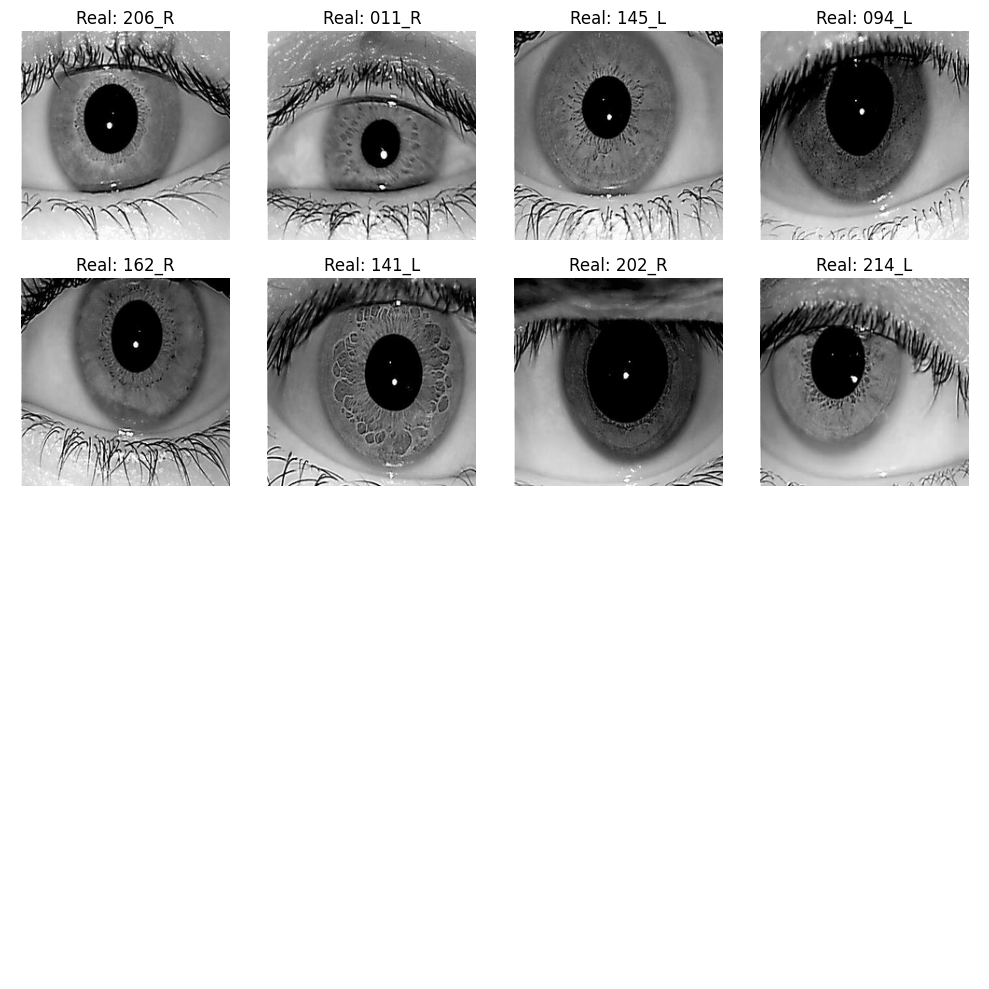

Generated sample grid:


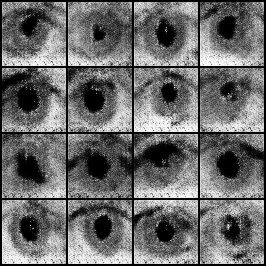


Grid file: /content/drive5/MyDrive/Ocular_Project/results/IITD/notebook06_gan_augmentation/training_samples/epoch_015.png
Generated grid size: (266, 266)


In [7]:

from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import torch
import pandas as pd

GAN_OUT = PROJECT / "results/IITD/notebook06_gan_augmentation"
SAMPLE_DIR = GAN_OUT / "training_samples"
FINAL_SAMPLE = SAMPLE_DIR / "epoch_015.png"

if not FINAL_SAMPLE.is_file():
    raise FileNotFoundError(f"Generated sample grid missing: {FINAL_SAMPLE}")

# Load the generated grid
generated_grid = Image.open(FINAL_SAMPLE).convert("L")

# Select real training examples
real_examples = manifest_df.sample(
    n=min(8, len(manifest_df)), random_state=42
).reset_index(drop=True)

fig, axes = plt.subplots(4, 4, figsize=(10, 10))

for i in range(8):
    with Image.open(real_examples.loc[i, "local_path"]) as im:
        axes.flat[i].imshow(im.convert("L"), cmap="gray")
    axes.flat[i].set_title(
        f"Real: {real_examples.loc[i, 'label_name']}"
    )
    axes.flat[i].axis("off")

# Display generated grid separately in the final two rows
for i in range(8, 16):
    axes.flat[i].axis("off")

plt.tight_layout()
plt.show()

print("Generated sample grid:")
display(generated_grid)

print("\nGrid file:", FINAL_SAMPLE)
print("Generated grid size:", generated_grid.size)


In [8]:

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.utils import save_image
from PIL import Image
from pathlib import Path
import pandas as pd
import time
import json

# --------------------------------------------------
# 1. Fixed configuration for the final improvement
# --------------------------------------------------
GAN2_SIZE = 128
GAN2_BATCH_SIZE = 16
GAN2_EPOCHS = 10
GAN2_LATENT_DIM = 100
GAN2_LR = 0.0002
GAN2_BETA1 = 0.5

torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

assert torch.cuda.is_available(), "Enable the T4 GPU before continuing."

GAN2_OUT = PROJECT / "results/IITD/notebook06_gan_augmentation/improved_128"
GAN2_MODEL_DIR = PROJECT / "models/IITD"
GAN2_SAMPLES = GAN2_OUT / "training_samples"

for folder in [GAN2_OUT, GAN2_MODEL_DIR, GAN2_SAMPLES]:
    folder.mkdir(parents=True, exist_ok=True)

GAN2_CHECKPOINT = GAN2_MODEL_DIR / "IITD_conditional_dcgan_128_latest.pth"
GAN2_HISTORY = GAN2_OUT / "IITD_gan_128_training_history.csv"

# --------------------------------------------------
# 2. Dataset at 128x128
# --------------------------------------------------
class IITDGAN128Dataset(Dataset):
    def __init__(self, manifest):
        self.manifest = manifest.reset_index(drop=True)
        self.transform = transforms.Compose([
            transforms.Resize((GAN2_SIZE, GAN2_SIZE)),
            transforms.ToTensor(),
            transforms.Normalize([0.5], [0.5])
        ])

    def __len__(self):
        return len(self.manifest)

    def __getitem__(self, idx):
        row = self.manifest.iloc[idx]
        with Image.open(row["local_path"]) as im:
            image = self.transform(im.convert("L"))
        return image, int(row["label"])

gan2_dataset = IITDGAN128Dataset(manifest_df)

gan2_loader = DataLoader(
    gan2_dataset,
    batch_size=GAN2_BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    drop_last=True
)

# --------------------------------------------------
# 3. Generator: 4 -> 8 -> 16 -> 32 -> 64 -> 128
# --------------------------------------------------
class ConditionalGenerator128(nn.Module):
    def __init__(self, latent_dim, num_classes):
        super().__init__()
        self.label_embedding = nn.Embedding(num_classes, 50)

        self.network = nn.Sequential(
            nn.ConvTranspose2d(latent_dim + 50, 512, 4, 1, 0, bias=False),
            nn.BatchNorm2d(512),
            nn.ReLU(True),

            nn.ConvTranspose2d(512, 256, 4, 2, 1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(True),

            nn.ConvTranspose2d(256, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(True),

            nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(True),

            nn.ConvTranspose2d(64, 32, 4, 2, 1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(True),

            nn.ConvTranspose2d(32, 1, 4, 2, 1),
            nn.Tanh()
        )

    def forward(self, noise, labels):
        labels_vec = self.label_embedding(labels)
        x = torch.cat([noise, labels_vec], dim=1)
        return self.network(x.unsqueeze(-1).unsqueeze(-1))

# --------------------------------------------------
# 4. Discriminator: 128 -> 64 -> 32 -> 16 -> 8 -> 4 -> 1
# --------------------------------------------------
class ConditionalDiscriminator128(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.label_embedding = nn.Embedding(
            num_classes, GAN2_SIZE * GAN2_SIZE
        )

        self.network = nn.Sequential(
            nn.Conv2d(2, 64, 4, 2, 1),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(64, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(128, 256, 4, 2, 1, bias=False),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(256, 512, 4, 2, 1, bias=False),
            nn.BatchNorm2d(512),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(512, 512, 4, 2, 1, bias=False),
            nn.BatchNorm2d(512),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(512, 1, 4, 1, 0)
        )

    def forward(self, images, labels):
        label_map = self.label_embedding(labels).view(
            -1, 1, GAN2_SIZE, GAN2_SIZE
        )
        x = torch.cat([images, label_map], dim=1)
        return self.network(x).view(-1)

# --------------------------------------------------
# 5. Initialize and verify
# --------------------------------------------------
G2 = ConditionalGenerator128(
    GAN2_LATENT_DIM, NUM_CLASSES
).to(DEVICE)

D2 = ConditionalDiscriminator128(NUM_CLASSES).to(DEVICE)

test_noise = torch.randn(2, GAN2_LATENT_DIM, device=DEVICE)
test_labels = torch.tensor([0, 1], device=DEVICE)

with torch.no_grad():
    test_images = G2(test_noise, test_labels)
    test_scores = D2(test_images, test_labels)

print("GPU:", torch.cuda.get_device_name(0))
print("Dataset images:", len(gan2_dataset))
print("Classes:", NUM_CLASSES)
print("Generator output:", tuple(test_images.shape))
print("Discriminator output:", tuple(test_scores.shape))
print("Batch size:", GAN2_BATCH_SIZE)
print("Epochs:", GAN2_EPOCHS)

assert test_images.shape == (2, 1, 128, 128)
assert test_scores.shape == (2,)

print("\nCell 7 complete. Improved models initialized.")


GPU: Tesla T4
Dataset images: 1526
Classes: 425
Generator output: (2, 1, 128, 128)
Discriminator output: (2,)
Batch size: 16
Epochs: 10

Cell 7 complete. Improved models initialized.


In [9]:

criterion2 = nn.BCEWithLogitsLoss()

optimizer_G2 = torch.optim.Adam(
    G2.parameters(), lr=GAN2_LR, betas=(GAN2_BETA1, 0.999)
)
optimizer_D2 = torch.optim.Adam(
    D2.parameters(), lr=GAN2_LR, betas=(GAN2_BETA1, 0.999)
)

history2 = []
fixed_noise2 = torch.randn(16, GAN2_LATENT_DIM, device=DEVICE)
fixed_labels2 = torch.arange(16, device=DEVICE) % NUM_CLASSES

for epoch in range(1, GAN2_EPOCHS + 1):
    G2.train()
    D2.train()
    start = time.time()
    loss_d_sum = 0.0
    loss_g_sum = 0.0
    batches = 0

    for real, labels in gan2_loader:
        real = real.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        bs = real.size(0)

        real_targets = torch.full((bs,), 0.9, device=DEVICE)
        fake_targets = torch.zeros(bs, device=DEVICE)

        # Train discriminator
        optimizer_D2.zero_grad(set_to_none=True)

        real_logits = D2(real, labels)
        loss_real = criterion2(real_logits, real_targets)

        noise = torch.randn(bs, GAN2_LATENT_DIM, device=DEVICE)
        fake = G2(noise, labels)
        fake_logits = D2(fake.detach(), labels)
        loss_fake = criterion2(fake_logits, fake_targets)

        loss_D = loss_real + loss_fake
        loss_D.backward()
        optimizer_D2.step()

        # Train generator
        optimizer_G2.zero_grad(set_to_none=True)

        noise = torch.randn(bs, GAN2_LATENT_DIM, device=DEVICE)
        generated = G2(noise, labels)
        generated_logits = D2(generated, labels)

        loss_G = criterion2(
            generated_logits, torch.ones(bs, device=DEVICE)
        )
        loss_G.backward()
        optimizer_G2.step()

        loss_d_sum += loss_D.item()
        loss_g_sum += loss_G.item()
        batches += 1

    record = {
        "epoch": epoch,
        "discriminator_loss": loss_d_sum / batches,
        "generator_loss": loss_g_sum / batches,
        "epoch_seconds": time.time() - start,
    }
    history2.append(record)

    G2.eval()
    with torch.no_grad():
        samples = G2(fixed_noise2, fixed_labels2)
        samples = (samples.clamp(-1, 1) + 1) / 2
        save_image(
            samples,
            GAN2_SAMPLES / f"epoch_{epoch:03d}.png",
            nrow=4
        )

    torch.save({
        "epoch": epoch,
        "generator": G2.state_dict(),
        "discriminator": D2.state_dict(),
        "optimizer_G": optimizer_G2.state_dict(),
        "optimizer_D": optimizer_D2.state_dict(),
        "history": history2,
        "config": {
            "image_size": GAN2_SIZE,
            "latent_dim": GAN2_LATENT_DIM,
            "num_classes": NUM_CLASSES,
            "batch_size": GAN2_BATCH_SIZE,
            "epochs": GAN2_EPOCHS,
            "learning_rate": GAN2_LR,
        }
    }, GAN2_CHECKPOINT)

    pd.DataFrame(history2).to_csv(GAN2_HISTORY, index=False)

    print(
        f"Epoch {epoch:02d}/{GAN2_EPOCHS} | "
        f"D: {record['discriminator_loss']:.4f} | "
        f"G: {record['generator_loss']:.4f} | "
        f"Time: {record['epoch_seconds'] / 60:.2f} min"
    )

summary2 = {
    "epochs_completed": len(history2),
    "training_images": len(gan2_dataset),
    "identity_classes": NUM_CLASSES,
    "training_resolution": GAN2_SIZE,
    "batch_size": GAN2_BATCH_SIZE,
    "checkpoint": str(GAN2_CHECKPOINT),
    "history_csv": str(GAN2_HISTORY),
    "samples_directory": str(GAN2_SAMPLES),
    "validation_used_for_gan_training": False,
    "test_used_for_gan_training": False,
    "note": (
        "Single improved GAN attempt. Image quality and identity "
        "preservation must be evaluated separately."
    )
}

with open(GAN2_OUT / "IITD_gan_128_summary.json", "w") as f:
    json.dump(summary2, f, indent=2)

print("\nImproved GAN training finished.")
print("Checkpoint:", GAN2_CHECKPOINT)
print("Samples:", GAN2_SAMPLES)


Epoch 01/10 | D: 1.1667 | G: 2.8433 | Time: 0.17 min
Epoch 02/10 | D: 1.1483 | G: 2.1883 | Time: 0.18 min
Epoch 03/10 | D: 1.0454 | G: 2.2834 | Time: 0.18 min
Epoch 04/10 | D: 0.9455 | G: 2.4462 | Time: 0.20 min
Epoch 05/10 | D: 0.8273 | G: 2.7107 | Time: 0.19 min
Epoch 06/10 | D: 0.7480 | G: 3.2841 | Time: 0.18 min
Epoch 07/10 | D: 0.6665 | G: 3.4325 | Time: 0.17 min
Epoch 08/10 | D: 0.6764 | G: 3.5866 | Time: 0.17 min
Epoch 09/10 | D: 0.6958 | G: 3.4828 | Time: 0.18 min
Epoch 10/10 | D: 0.6125 | G: 3.7470 | Time: 0.19 min

Improved GAN training finished.
Checkpoint: /content/drive5/MyDrive/Ocular_Project/models/IITD/IITD_conditional_dcgan_128_latest.pth
Samples: /content/drive5/MyDrive/Ocular_Project/results/IITD/notebook06_gan_augmentation/improved_128/training_samples


Improved GAN — epoch 10
Resolution during training: 128 x 128
Grid: /content/drive5/MyDrive/Ocular_Project/results/IITD/notebook06_gan_augmentation/improved_128/training_samples/epoch_010.png


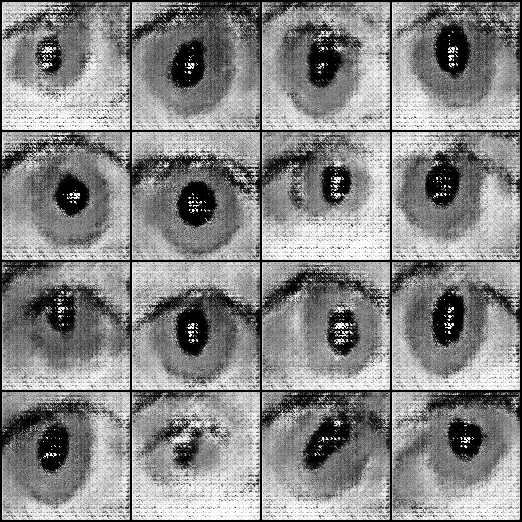

In [10]:

from pathlib import Path
from PIL import Image
from IPython.display import display

GAN2_SAMPLES = (
    PROJECT / "results/IITD/notebook06_gan_augmentation/"
    "improved_128/training_samples"
)
FINAL_SAMPLE_128 = GAN2_SAMPLES / "epoch_010.png"

if not FINAL_SAMPLE_128.is_file():
    raise FileNotFoundError(
        f"Final sample grid not found: {FINAL_SAMPLE_128}"
    )

print("Improved GAN — epoch 10")
print("Resolution during training: 128 x 128")
print("Grid:", FINAL_SAMPLE_128)

display(Image.open(FINAL_SAMPLE_128))


In [11]:

from pathlib import Path
from PIL import Image
from torchvision.transforms.functional import resize
from torchvision.utils import save_image
import torch
import pandas as pd
import json

# --------------------------------------------------
# 1. Output paths
# --------------------------------------------------
GAN2_OUT = PROJECT / "results/IITD/notebook06_gan_augmentation/improved_128"
SYNTH_DIR = PROJECT / "generated_images/IITD/gan"
SYNTH_DIR.mkdir(parents=True, exist_ok=True)

SYNTH_METADATA = GAN2_OUT / "IITD_GAN_synthetic_metadata.csv"
SYNTH_SUMMARY = GAN2_OUT / "IITD_GAN_synthetic_summary.json"

# --------------------------------------------------
# 2. Load the final improved generator checkpoint
# --------------------------------------------------
checkpoint = torch.load(
    GAN2_CHECKPOINT,
    map_location=DEVICE,
    weights_only=False
)
G2.load_state_dict(checkpoint["generator"])
G2.eval()

SAMPLES_PER_CLASS = 3
BATCH_GEN = 32
records = []
generated_count = 0

# --------------------------------------------------
# 3. Generate samples in batches
# --------------------------------------------------
with torch.no_grad():
    for label in range(NUM_CLASSES):
        for sample_idx in range(SAMPLES_PER_CLASS):
            noise = torch.randn(1, GAN2_LATENT_DIM, device=DEVICE)
            label_tensor = torch.tensor([label], device=DEVICE)

            image = G2(noise, label_tensor)
            image = (image.clamp(-1, 1) + 1) / 2

            # Upsample to the common downstream image size.
            image_224 = resize(
                image,
                [224, 224],
                antialias=True
            )

            label_name = (
                manifest_df.loc[
                    manifest_df["label"] == label, "label_name"
                ].iloc[0]
            )

            filename = f"label_{label:03d}_sample_{sample_idx + 1:02d}.png"
            class_dir = SYNTH_DIR / label_name
            class_dir.mkdir(parents=True, exist_ok=True)
            output_path = class_dir / filename

            save_image(image_224, output_path)

            records.append({
                "synthetic_path": str(output_path),
                "filename": filename,
                "label": label,
                "label_name": label_name,
                "sample_index": sample_idx + 1,
                "source_model": "IITD_conditional_dcgan_128",
                "native_resolution": "128x128",
                "saved_resolution": "224x224",
                "identity_preservation_verified": False,
                "split": "synthetic_train_candidate",
            })
            generated_count += 1

        if (label + 1) % 50 == 0:
            print(f"Processed {label + 1}/{NUM_CLASSES} labels")

# --------------------------------------------------
# 4. Save and verify metadata
# --------------------------------------------------
metadata_df = pd.DataFrame(records)
metadata_df.to_csv(SYNTH_METADATA, index=False)

assert generated_count == NUM_CLASSES * SAMPLES_PER_CLASS
assert metadata_df["synthetic_path"].map(
    lambda p: Path(p).is_file()
).all()

summary = {
    "synthetic_images_generated": int(generated_count),
    "identity_classes_conditioned": int(NUM_CLASSES),
    "samples_per_class": SAMPLES_PER_CLASS,
    "native_resolution": "128x128",
    "saved_resolution": "224x224",
    "model_checkpoint": str(GAN2_CHECKPOINT),
    "metadata_csv": str(SYNTH_METADATA),
    "output_directory": str(SYNTH_DIR),
    "identity_preservation_verified": False,
    "visual_quality_limitation": (
        "Visible artifacts and blurred iris details in the inspected samples."
    ),
    "usage_warning": (
        "Do not assume synthetic labels are correct biometric identities. "
        "Evaluate quality and recognition performance before using these "
        "images to support performance claims."
    ),
}

with open(SYNTH_SUMMARY, "w") as f:
    json.dump(summary, f, indent=2)

print("\nGeneration complete.")
print("Synthetic images:", generated_count)
print("Unique proposed labels:", metadata_df["label"].nunique())
print("Metadata:", SYNTH_METADATA)
print("Summary:", SYNTH_SUMMARY)
print("Image directory:", SYNTH_DIR)



Processed 50/425 labels
Processed 100/425 labels
Processed 150/425 labels
Processed 200/425 labels
Processed 250/425 labels
Processed 300/425 labels
Processed 350/425 labels
Processed 400/425 labels

Generation complete.
Synthetic images: 1275
Unique proposed labels: 425
Metadata: /content/drive5/MyDrive/Ocular_Project/results/IITD/notebook06_gan_augmentation/improved_128/IITD_GAN_synthetic_metadata.csv
Summary: /content/drive5/MyDrive/Ocular_Project/results/IITD/notebook06_gan_augmentation/improved_128/IITD_GAN_synthetic_summary.json
Image directory: /content/drive5/MyDrive/Ocular_Project/generated_images/IITD/gan


# Conclusion — GAN-Based Synthetic Ocular Image Generation

In this notebook, a conditional Deep Convolutional Generative Adversarial Network (DCGAN) was trained on the IIT Delhi ocular dataset using only the 1,526 training images belonging to 425 subject-eye identity classes.

Two experiments were conducted:

- **Experiment 1:** 64×64 resolution for 15 epochs.
- **Experiment 2:** 128×128 resolution for 10 epochs.

The second experiment used a higher-resolution generator and discriminator in an attempt to improve synthetic image quality. Visual inspection showed eye-like structures in the generated samples, but noticeable artifacts, blurred iris textures, and irregular pupil details remained. Increasing the resolution did not establish that the model generated reliable biometric samples.

Following the second experiment, 1,275 synthetic images were generated at 128×128 and resized to 224×224. Three images were generated per proposed identity label, covering 425 labels. The images and their metadata were saved separately from the original dataset and traditional augmentation outputs.

## Limitations

1. The dataset contains relatively few training images per identity class.
2. Visual quality remains limited, and identity preservation has not been verified.
3. A conditioning label is not proof that a synthetic image represents the corresponding person or eye.
4. Resizing generated images does not restore fine iris details lost during low-resolution generation.
5. GAN losses and visual inspection alone cannot establish improved recognition performance or privacy protection.

## Conclusion

The GAN experiments establish a baseline for comparing GAN-based ocular image generation with traditional augmentation and diffusion-based generation. The model was not further tuned after the single planned improvement attempt. Synthetic images should be treated as experimental candidates until their quality, identity consistency, and downstream recognition impact are evaluated.

The next stage is diffusion-model training, followed by a controlled comparison of augmentation methods using consistent data splits and evaluation procedures.